In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [2]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [3]:
import h5py
from astropy.io import ascii

In [4]:
from lmfit import Model

In [5]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [6]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [7]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs_test.h5','r')

In [8]:
data

<HDF5 file "coadds_outputs_test.h5" (mode r)>

In [9]:
data.keys()

<KeysViewHDF5 ['EXPRES', 'NEID', 'overlaps']>

In [10]:
data['NEID']

<HDF5 group "/NEID" (4 members)>

In [11]:
data['NEID'].keys()

<KeysViewHDF5 ['coadds', 'date_sets', 'uncs', 'wls']>

In [12]:
for key in data['NEID']['coadds'].keys():
    #if the shape is greater than 1, print the key and shape
    if data['NEID']['coadds'][key].shape[0]>1:
        print(key, data['NEID']['coadds'][key].shape)

0076 (113, 9216)
0077 (113, 9216)


In [13]:
list(data['NEID']['coadds']['0076'])

[array([        nan,         nan,         nan, ..., -0.09486013,
        -0.25144505,         nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([ 0.36145929, -0.09031449,  0.04698045, ...,  0.10456941,
         0.07020358,  0.0979645 ]),
 array([-0.26164488, -0.11676299,  0.07383982, ...,  0.01246092,
         0.04076705,  0.03874096]),
 array([ 0.03002849,  0.1437714 , -0.03473961, ...,  0.25129229,
         0.22745566,  0.27824111]),
 array([ 0.07084621,  0.04583163, -0.15286647, ...,  0.23318423,
         0.22382259,  0.23645968]),
 array([-0.24641787, -0.13452859, -0.17907772, ...,  0.35217825,
         0.34645102,  0.37372533]),
 array([-0.12393355, -0.04611374,  0.02275389, ...,  0.53088118,
         0.50550627,  0.5171935 ]),
 array([0.16895225, 0.13815465, 0.22237936, ..., 0.33676491, 0.32067552,
        0.32110295]),
 array([0.21334356, 0.29384583, 0.21540377, ..., 0.55924039, 0.55592462,
        0.56657723]),
 array([0.019

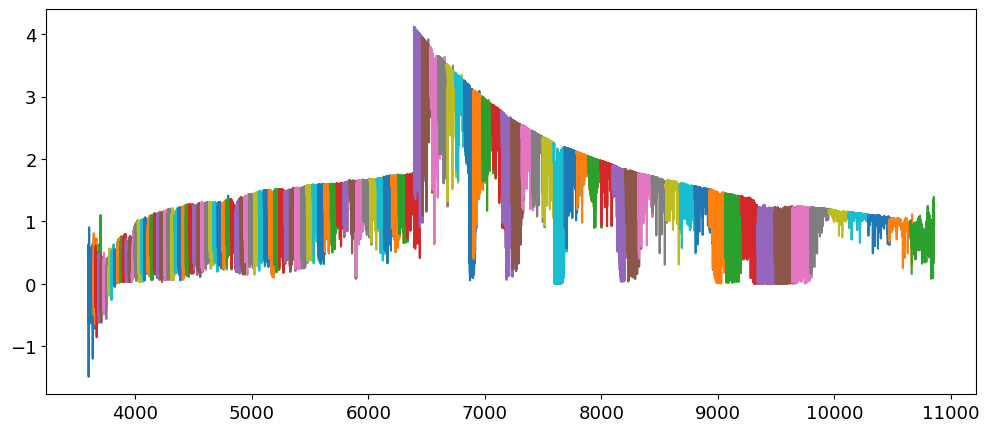

In [14]:
for o in range(data['NEID']['coadds']['0076'].shape[0]):
    #if the mean wavelength is greater than 1000, plot the coadd
    if np.mean(data['NEID']['wls']['0076'][o])>1000:
        plt.plot(data['NEID']['wls']['0076'][o],data['NEID']['coadds']['0076'][o])

In [15]:
np.array(data['NEID']['coadds']['0076'])

array([[        nan,         nan,         nan, ..., -0.09486013,
        -0.25144505,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       ...,
       [ 1.04341285,  1.04062005,  1.04613465, ...,  0.92511029,
         0.94662709,  0.93732712],
       [ 0.91320244,  0.87391946,  0.89074361, ...,  0.91730876,
         0.88672567,  0.83337657],
       [ 0.73465386,  0.74403111,  0.81134346, ...,  1.05641389,
         1.00538673,  0.98943148]])

In [16]:
np.array(data['NEID']['coadds'])

array(['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007',
       '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015',
       '0016', '0017', '0018', '0019', '0020', '0021', '0022', '0023',
       '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031',
       '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039',
       '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047',
       '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055',
       '0056', '0057', '0058', '0059', '0060', '0061', '0062', '0063',
       '0064', '0065', '0066', '0067', '0068', '0069', '0070', '0071',
       '0072', '0073', '0074', '0075', '0076', '0077', '0078', '0079',
       '0080', '0081', '0082', '0083', '0084', '0085', '0086', '0087',
       '0088', '0089', '0090', '0091', '0092', '0093', '0094', '0095',
       '0096', '0097', '0098', '0099', '0100', '0101', '0102', '0103',
       '0104', '0105', '0106', '0107', '0108', '0109', '0110', '0111',
      

In [17]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]

for key in  data['NEID']['coadds'].keys():
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)

NEID coadds found for key: 0076
EXPRES coadds found for key: 0076
NEID coadds found for key: 0077
EXPRES coadds found for key: 0077


In [18]:
#read in csv file with line list
line_list_loc="../../RvLineList_allowBlends=0_overlapCutoff=5.0e-6_blend_RV_cutoff=2.0_depthCutoff=0.02_rejectTelluricSlope=2000.0_badLineFilter=none_quant=95_nbin=1_DP=true_binParam=depth_n=1_long_output=true_VACUUM.csv"

In [19]:
line_list=ascii.read(line_list_loc)

In [20]:
gmod=Model(gaussian_w_slope)

In [21]:
w=np.array(data['NEID']['wls']['0076'])
s=np.array(data['NEID']['coadds']['0076'])

In [35]:


def fit_lines(w,s,line_list,plot=False,wl_min=6000,wl_max=6030,fit_range=0.7,dist_from_edge=500):
    line_fits=[]
    '''fits lines in line_list to the spectrum s with wavelengths w
    
        inputs are:
            w: 2D array of wavelengths (orders x pixels)
            s: 2D array of spectrum (orders x pixels)
            line_list: astropy table with columns 'lambda' and 'depth'
    '''
    for i,l in enumerate(line_list['lambda'].value):
        if l<wl_max and l>wl_min:
            #print(l,line_list['depth'][i])
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            orders_with_line=[] 

            for o in range(w.shape[0]):
                if l>w[o].min()+dist_from_edge*(w[o][1]-w[o][0]) and l<w[o].max()-dist_from_edge*(w[o][1]-w[o][0]):
                    orders_with_line.append(o)
            #print("orders with line:",orders_with_line)
            #for each order, convert the wavelength to velocity, centered on the line wavelength and then fit a guassian to the spectrum
            #only fit within 2 angstroms of the line center
            for o in orders_with_line: 
                wl_order=w[o]
                s_order=s[o]
                vel_order=wl2vel(wl_order,central_wl=l)
                #select only the points within 1 angstroms of the line center and the spectrum is not NaN
                mask=(wl_order>l-fit_range)&(wl_order<l+fit_range)&(~np.isnan(s_order))
                wl_fit=wl_order[mask]
                s_fit=s_order[mask]
                vel_fit=vel_order[mask]
                #save the pixel index of the line center
                line_center_index=np.argmin(np.abs(wl_order-l))
                #initial guess for the gaussian parameters
                amp_init=line_list['depth'][i]*np.sum(s_fit)*-1
                cen_init=0
                wid_init=3.0
                bas_init=np.median(s_fit)
                slope_init=0
                params=gmod.make_params(amp=amp_init,cen=cen_init,wid=wid_init,bas=bas_init,slope=slope_init)
                #fit the gaussian to the data
                try:
                    result=gmod.fit(s_fit,params,x=vel_fit)
                    #now refit after dividing by the best fit baseline + slope
                    s_fit_detrended=s_fit/(result.params['bas'].value+vel_fit*result.params['slope'].value)
                    params=gmod.make_params(amp=amp_init,cen=cen_init,wid=wid_init,bas=0,slope=0)
                    result=gmod.fit(s_fit_detrended,params,x=vel_fit)
                
                except:
                    print(f"Fit failed for line at {l} Angstroms in order {o}")
                    print(wl_fit)
                    print(s_fit)
                    continue               
                #print(result.fit_report())
                if plot:
                    #plot the data and the fit
                    plt.figure()
                    plt.plot(vel_fit,s_fit_detrended,label='data')
                    plt.plot(vel_fit,result.best_fit,label='fit')
                    plt.xlabel('Velocity (km/s)')
                    plt.ylabel('Flux')
                    plt.title(f'Order {o} Line at {l} Angstroms')
                    plt.legend()
                    plt.show()
                

                
                #save the fit results to a list
                line_fits.append({'line_wl':l,'order':o,'amp':result.params['amp'].value,'amp_err':result.params['amp'].stderr,    
                                  'cen':result.params['cen'].value,
                                  'cen_err':result.params['cen'].stderr,
                                  'wid':result.params['wid'].value,
                                  'wid_err':result.params['wid'].stderr,
                                  'bas':result.params['bas'].value,
                                  'bas_err':result.params['bas'].stderr,
                                  'slope':result.params['slope'].value,'chi2':result.chisqr,
                                  'bic':result.bic,'r':result.rsquared,
                                  'line_center_index':line_center_index})
    
    return line_fits
            

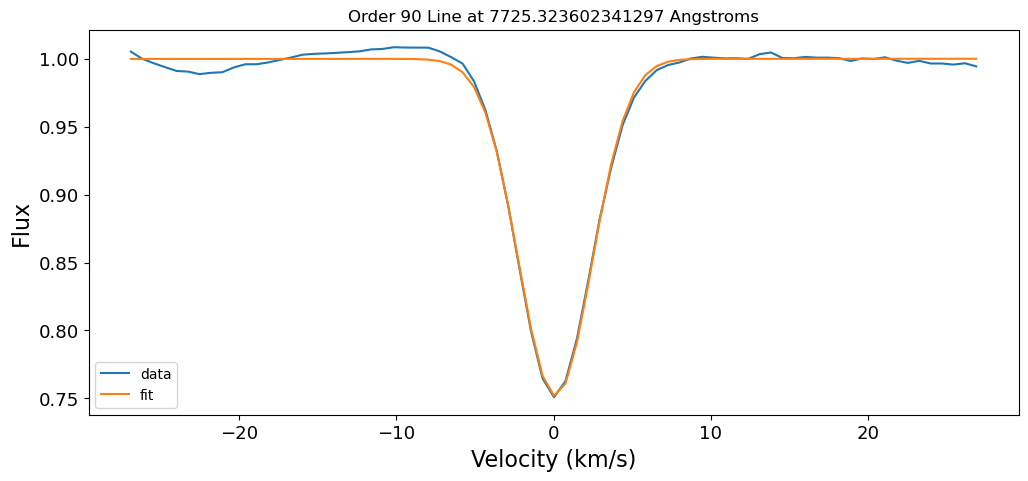

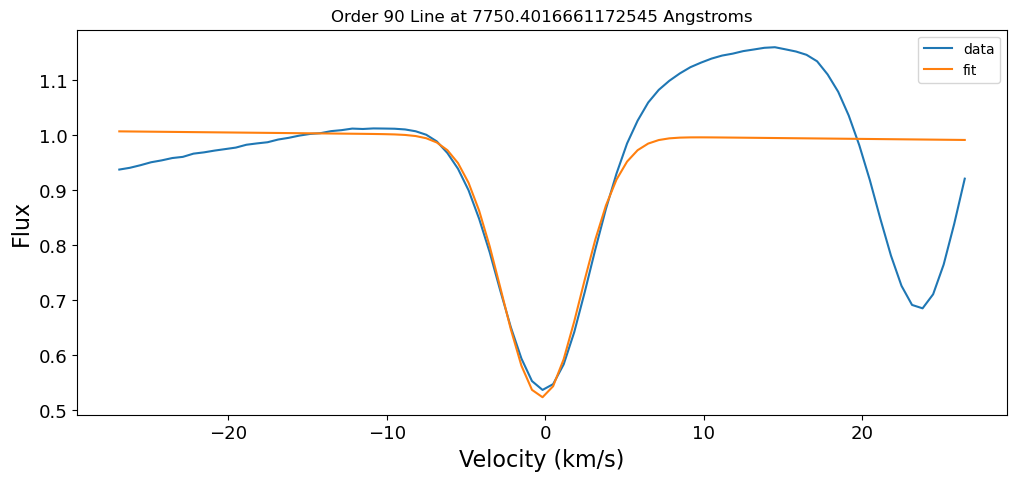

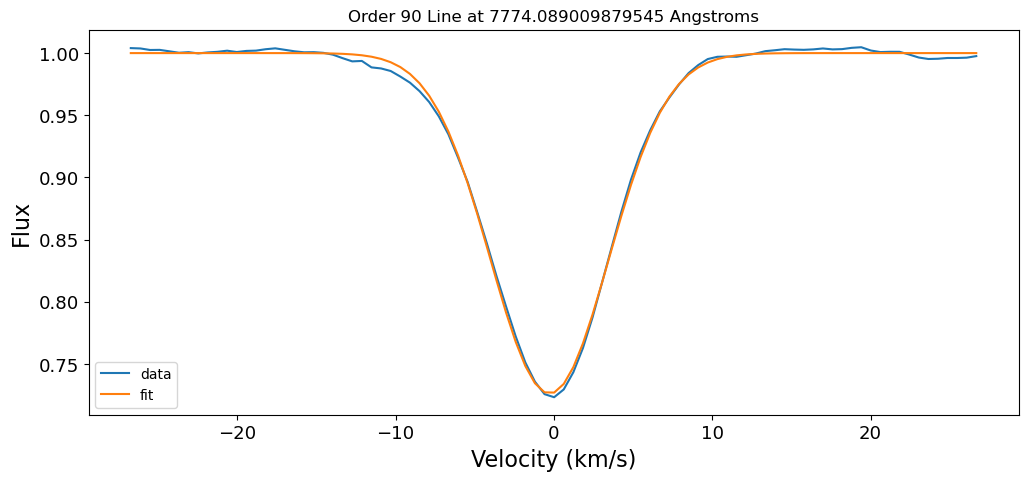

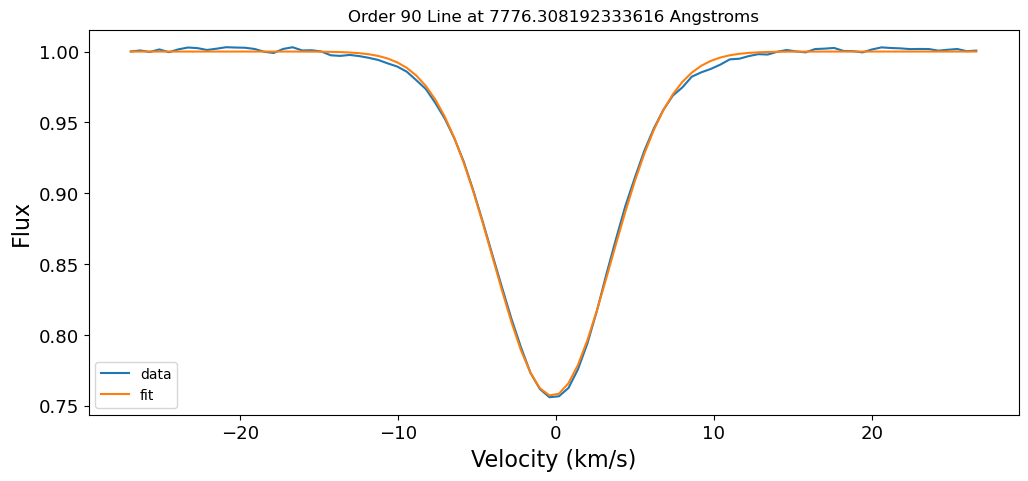

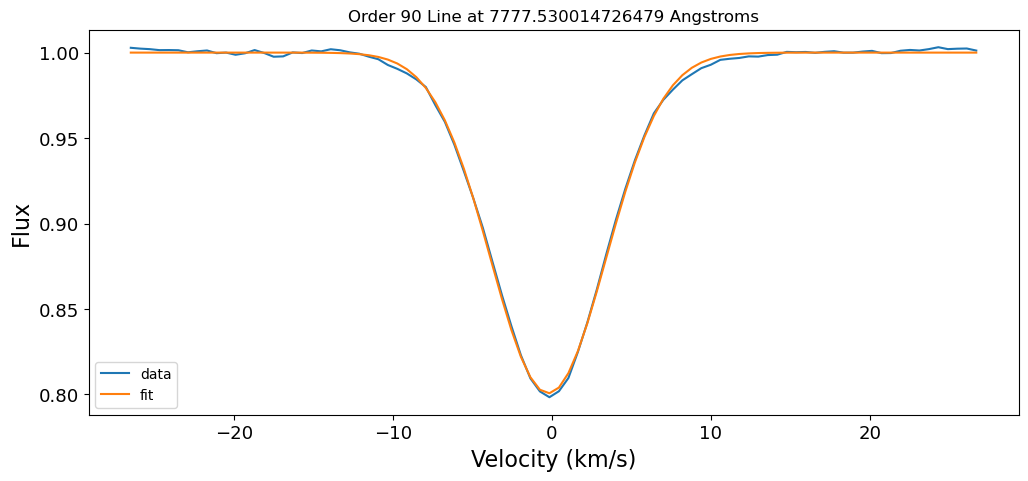

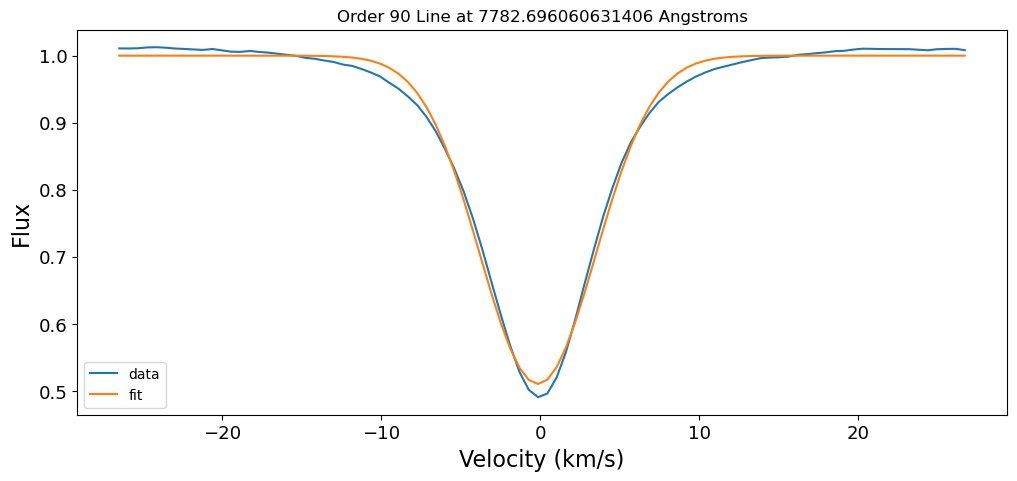

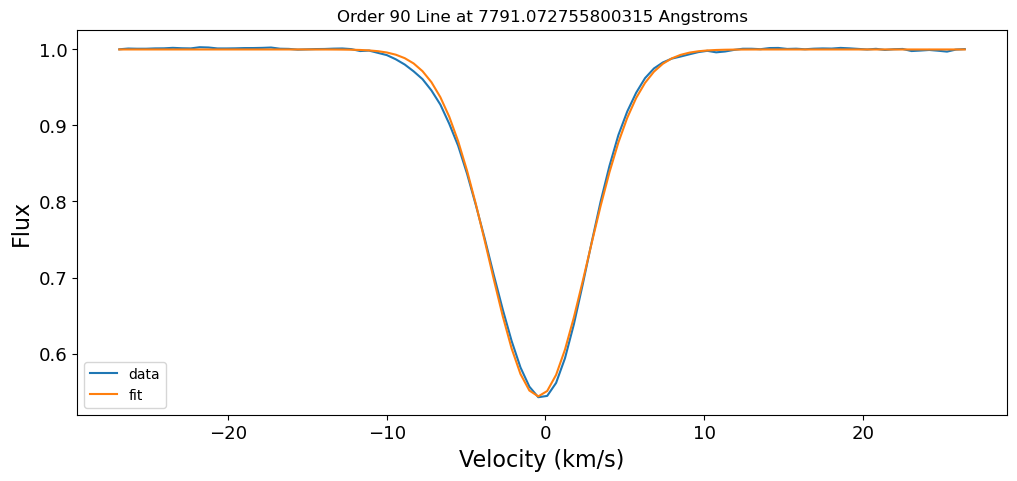

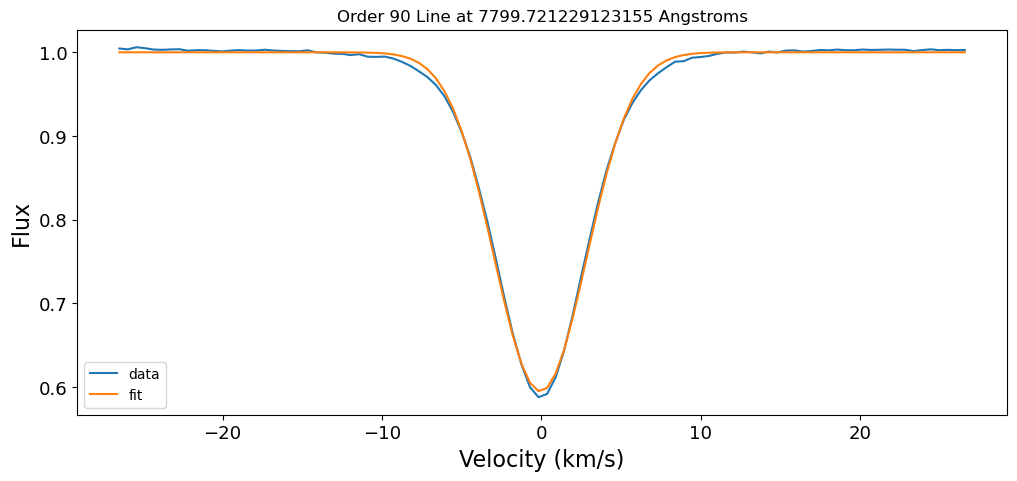

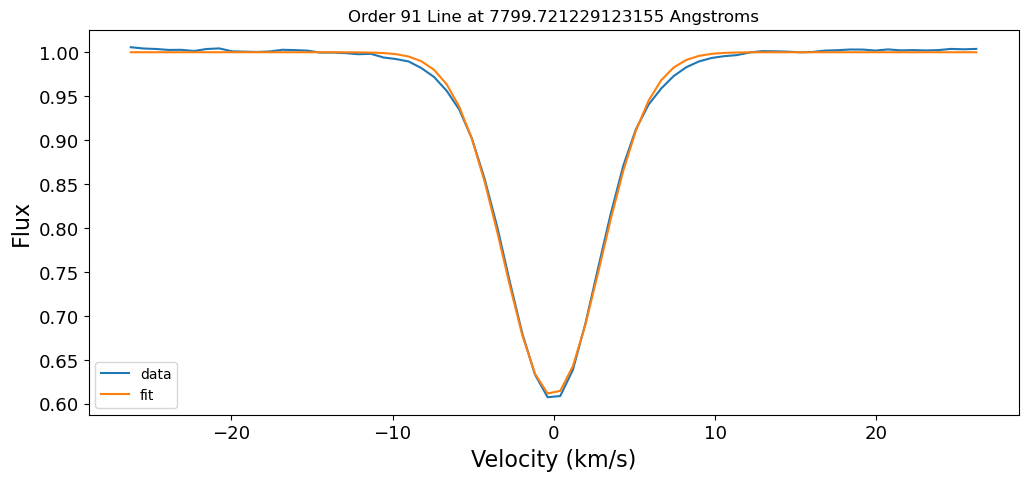

In [36]:
fit_res=fit_lines(w,s,line_list,plot=True,wl_min=7600,wl_max=7800,fit_range=0.7,dist_from_edge=500)

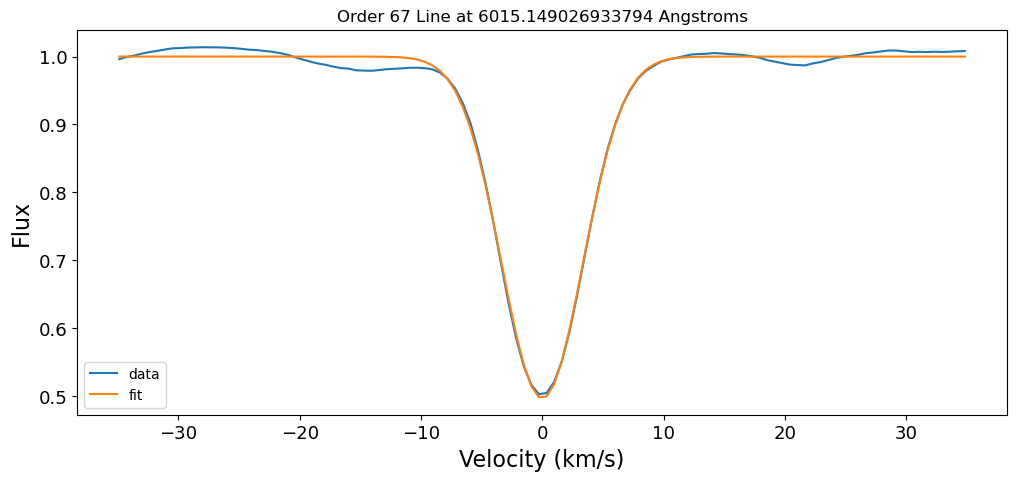

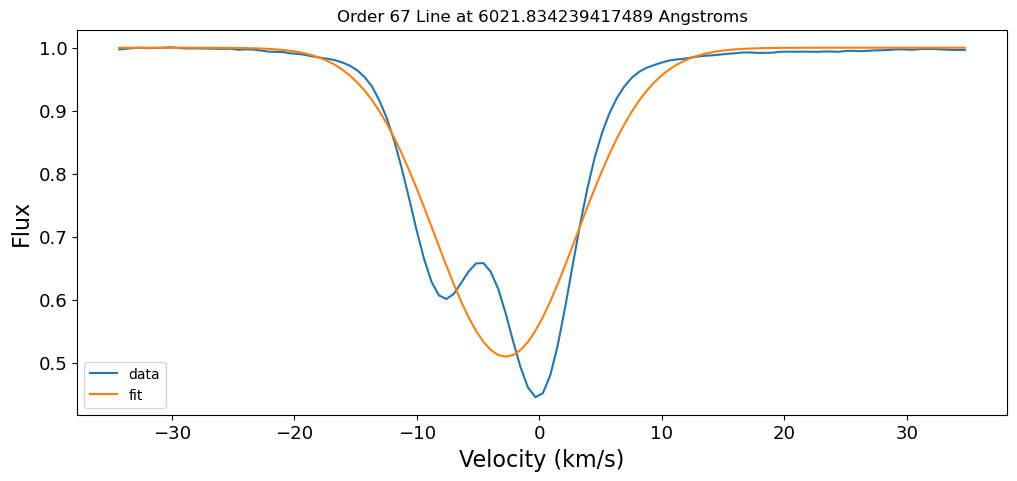

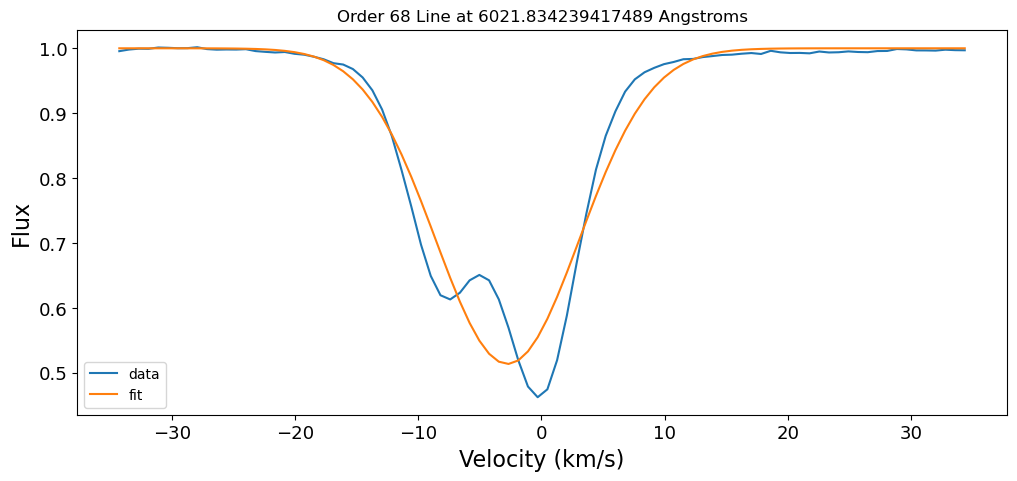

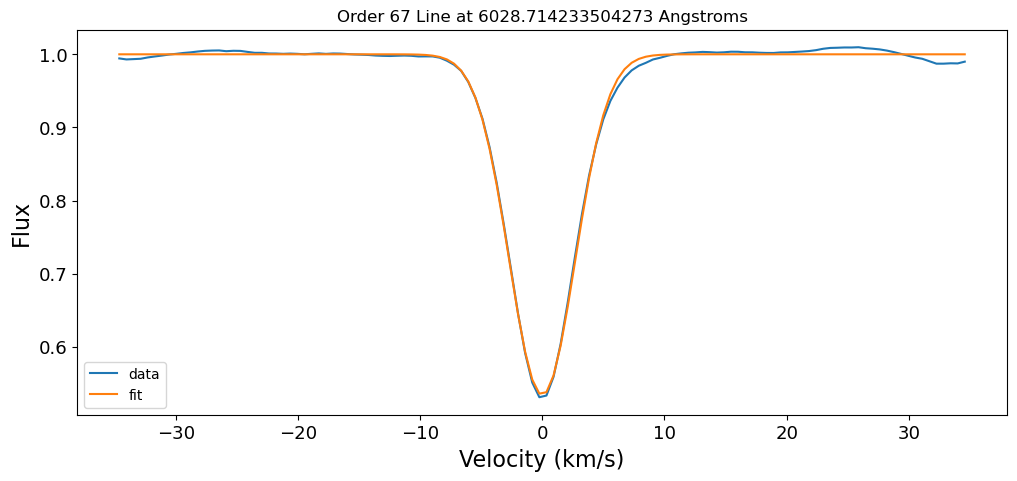

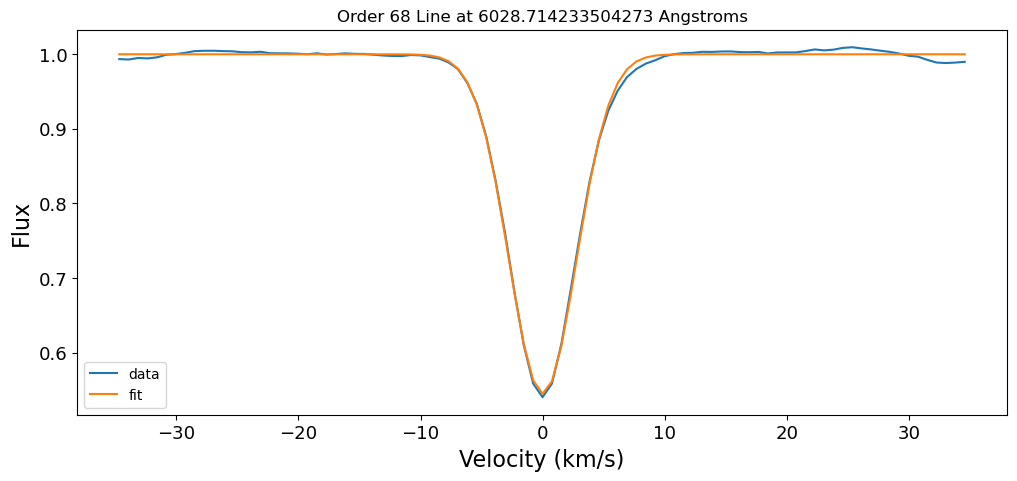

In [37]:
fit_res=fit_lines(w,s,line_list,plot=True,wl_min=6000,wl_max=6030,fit_range=0.7,dist_from_edge=500)

In [38]:
fit_res

[{'line_wl': 6015.149026933794,
  'order': 67,
  'amp': -4.224275687178118,
  'amp_err': 0.03453910429059276,
  'cen': -0.011841487794337259,
  'cen_err': 0.027442341514009087,
  'wid': 3.3479400431644595,
  'wid_err': 0.028818321114344236,
  'bas': 0.9999999761424515,
  'bas_err': 0.0009761888438715779,
  'slope': -1.8964733116310187e-07,
  'chi2': 0.008528963194621531,
  'bic': -1038.4795762019028,
  'r': 0.9957336262513774,
  'line_center_index': 4382},
 {'line_wl': 6021.834239417489,
  'order': 67,
  'amp': -7.123105504558255,
  'amp_err': 0.2397949393613298,
  'cen': -2.7442206955947395,
  'cen_err': 0.17094559188435537,
  'wid': 5.795001460757329,
  'wid_err': 0.18820969709282248,
  'bas': 1.000009781660997,
  'bas_err': 0.005154712166774042,
  'slope': 5.906639737084452e-08,
  'chi2': 0.18547265753701342,
  'bic': -715.7000318698962,
  'r': 0.9394100719274263,
  'line_center_index': 4923},
 {'line_wl': 6021.834239417489,
  'order': 68,
  'amp': -7.09814136846411,
  'amp_err': 0.

In [39]:
fit_lines(w,s/1.6,line_list,wl_min=6000,wl_max=6030,fit_range=1,dist_from_edge=500)

[{'line_wl': 6015.149026933794,
  'order': 67,
  'amp': -4.242906984711547,
  'amp_err': 0.03172976096330573,
  'cen': -0.013180047792432198,
  'cen_err': 0.026338742864927874,
  'wid': 3.3609065242915577,
  'wid_err': 0.027235249226545893,
  'bas': 1.0000000219196308,
  'bas_err': 0.0007512503908455089,
  'slope': -7.05849442572448e-08,
  'chi2': 0.011343902101200249,
  'bic': -1492.7841624805405,
  'r': 0.9946760553646405,
  'line_center_index': 4382},
 {'line_wl': 6021.834239417489,
  'order': 67,
  'amp': -7.029539311190708,
  'amp_err': 0.1815294320020258,
  'cen': -2.7196918018989527,
  'cen_err': 0.14322682252485908,
  'wid': 5.733334826066742,
  'wid_err': 0.15229499031607197,
  'bas': 1.000012082515774,
  'bas_err': 0.003294595869997751,
  'slope': 3.3613898865639074e-07,
  'chi2': 0.19594063394786315,
  'bic': -1078.1895048230688,
  'r': 0.9421905539962281,
  'line_center_index': 4923},
 {'line_wl': 6021.834239417489,
  'order': 68,
  'amp': -6.996331316563327,
  'amp_err': 0

In [27]:
#time how long this cell takes to run
%time ff=fit_lines(w,s/1.6,line_list,wl_min=3800,wl_max=9030,fit_range=1,dist_from_edge=500)

CPU times: user 27.7 s, sys: 165 ms, total: 27.8 s
Wall time: 28.1 s


In [28]:
len(ff)

3234

In [29]:
time_per_spec=25.7
dates=400
specs=2
total_time=time_per_spec*dates*specs/3600  #in hours
print(total_time)

5.711111111111111
